# Sentiment Analysis of Movie Reviews

## 1. Introduction

Sentiment analysis is a Natural Language Processing (NLP) task that aims to identify the emotional polarity of a text, such as whether a review expresses a positive or negative opinion. It can be used to automatically analyse large collections of textual data and extract opinions without manually reviewing every text.

In this project, sentiment analysis is applied to a dataset of 50,000 movie reviews containing positive and negative sentiment labels. Three different approaches are compared: VADER, a lexicon- and rule-based sentiment analysis method; RoBERTa, a pretrained transformer model capable of considering contextual relationships between words; and DistilBERT, a smaller transformer model designed to provide efficient text classification. The goal is to evaluate and compare their performance using accuracy, precision, recall, F1-score, and confusion matrices, and to investigate the types of reviews that are most difficult for each model.

## 2. Load and Explore the Dataset

The dataset contains 50,000 movie reviews labelled as either positive or negative. Before applying the sentiment models, I first inspect the dataset structure and the distribution of the two sentiment classes.


In [1]:
import re
import contractions
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
 
import nltk

In [2]:
df = pd.read_csv("mvreviews.csv")
print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


The reviews contain HTML line breaks (`<br />`), which are not part of the actual text. I remove them, expand contractions, and normalise whitespace. I deliberately do not lowercase the text or remove punctuation, since VADER uses capitalisation and exclamation marks as intensity cues.

In [3]:
def clean_review(text):
    text = re.sub(r"<.*?>", " ", text)      # remove HTML tags like <br />
    text = contractions.fix(text)           # don't -> do not
    text = re.sub(r"\s+", " ", text).strip() 
    return text

df["review"] = df["review"].apply(clean_review)

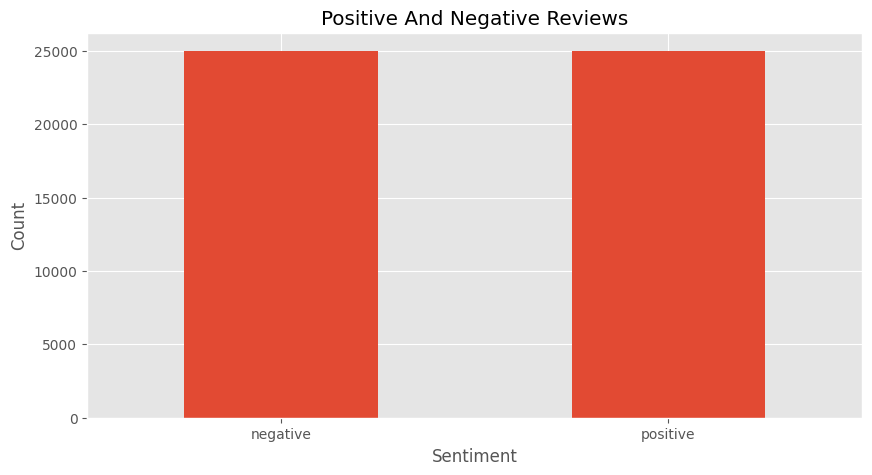

In [4]:
df["sentiment"].value_counts().sort_index().plot(kind='bar',
                                                title='Positive And Negative Reviews',
                                                figsize=(10, 5))

plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

## 3. VADER Sentiment Analysis 
VADER (Valence Aware Dictionary and sEntiment Reasoner) is a rule- and lexicon-based method for analyzing sentiment. It determines sentiment by looking at individual words and applying certain linguistic rules. However, unlike transformer-based models, VADER does not fully understand the context or relationships between words in a sentence.

In [ ]:
nltk.download('vader_lexicon')

In [6]:
from nltk.sentiment import SentimentIntensityAnalyzer
from tqdm.notebook import tqdm

sia = SentimentIntensityAnalyzer() 

In [7]:
results = {}
for i, row in tqdm(df.iterrows(), total=len(df)):
    text = row["review"]
    results[i] = sia.polarity_scores(text)

  0%|          | 0/50000 [00:00<?, ?it/s]

In [8]:
df = df.reset_index().rename(columns={'index': 'Id'})
vaders = pd.DataFrame(results).T.reset_index().rename(columns={'index': 'Id'})
vaders = vaders.merge(df, on='Id', how='left')
print(vaders.head())

   Id    neg    neu    pos  compound  \
0   0  0.202  0.750  0.048   -0.9951   
1   1  0.055  0.768  0.177    0.9641   
2   2  0.093  0.689  0.218    0.9780   
3   3  0.137  0.777  0.086   -0.8819   
4   4  0.052  0.786  0.162    0.9803   

                                              review sentiment  
0  One of the other reviewers has mentioned that ...  positive  
1  A wonderful little production. The filming tec...  positive  
2  I thought this was a wonderful way to spend ti...  positive  
3  Basically there is a family where a little boy...  negative  
4  Petter Mattei's "Love in the Time of Money" is...  positive  


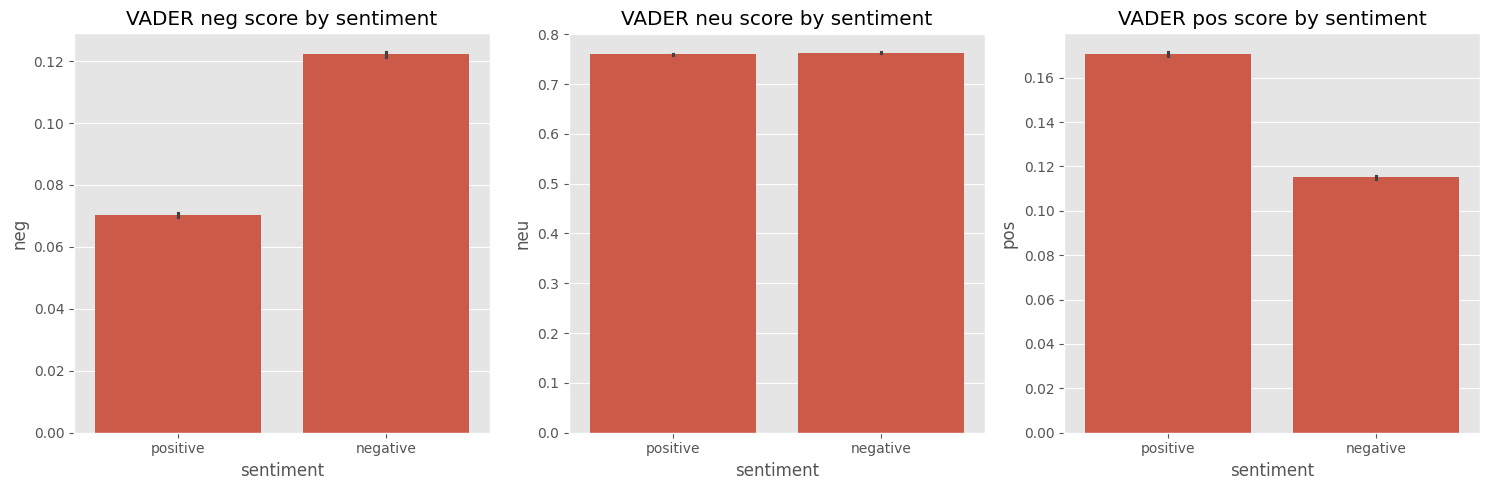

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(["neg", "neu", "pos"]):
    sns.barplot(data=vaders, x="sentiment", y=col, ax=axes[i])
    axes[i].set_title(f"VADER {col} score by sentiment")

plt.tight_layout()
plt.show()

## 4. RoBERTa Sentiment Analysis

RoBERTa is a pretrained transformer model that considers the context in which words appear, allowing it to capture relationships between words more effectively than lexicon-based methods such as VADER.

In [10]:
from transformers import AutoTokenizer 
from transformers import AutoModelForSequenceClassification
from scipy.special import softmax

In [11]:
MODEL = "cardiffnlp/twitter-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForSequenceClassification.from_pretrained(MODEL)
model = model.to('cuda') 

/usr/local/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


### Example Prediction

Before comparing the two models on the full dataset, I look at a single review to see what kind of scores each one produces. First, the VADER scores:

In [12]:
# Vader Results on text

text = df["review"][0]
print(text)
sia.polarity_scores(text)

One of the other reviewers has mentioned that after watching just 1 Oz episode you will be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word. It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Them City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away. I would say the main appeal of the show is due to the fact that it goes where other sh

{'neg': 0.202, 'neu': 0.75, 'pos': 0.048, 'compound': -0.9951}

The same review is then passed to RoBERTa to compare how a contextual transformer model evaluates the sentiment:

In [13]:
# Roberta Results on text

encoded_text = tokenizer(text, return_tensors='pt', max_length=512, truncation=True)
encoded_text = {k: v.to('cuda') for k, v in encoded_text.items()}
output = model(**encoded_text)
scores = output[0][0].detach().cpu().numpy()
scores = softmax(scores)
scores_dict = {
    'roberta_neg' : scores[0],
    'roberta_neu' : scores[1],
    'roberta_pos' : scores[2]
}

print(scores_dict)


{'roberta_neg': 0.37836438, 'roberta_neu': 0.4558148, 'roberta_pos': 0.16582078}


In [14]:
def polarity_scores_roberta(example):
    encoded_text = tokenizer(example, return_tensors='pt', max_length=512, truncation=True)
    encoded_text = {k: v.to('cuda') for k, v in encoded_text.items()}
    output = model(**encoded_text)
    scores = output.logits[0].detach().cpu().numpy()
    scores = softmax(scores)
    scores_dict = {
        'roberta_neg' : scores[0],
        'roberta_neu' : scores[1],
        'roberta_pos' : scores[2]
    }
    return scores_dict

In [15]:
results = {}
for i, row in tqdm(df.iterrows(), total=len(df)):
    text = row["review"]
    vader_result = sia.polarity_scores(text)
    vader_result_rename = {}
    for key, value in vader_result.items():
        vader_result_rename[f"vader_{key}"] = value
        
    roberta_result = polarity_scores_roberta(text)

    results[i] = {**vader_result_rename, **roberta_result}

  0%|          | 0/50000 [00:00<?, ?it/s]

In [16]:
results_df = pd.DataFrame(results).T
results_df = results_df.reset_index().rename(columns = {"index" : "Id"})
results_df = results_df.merge(df[["Id", "sentiment"]], on="Id", how="left")
print(results_df.head())

   Id  vader_neg  vader_neu  vader_pos  vader_compound  roberta_neg  \
0   0      0.202      0.750      0.048         -0.9951     0.378364   
1   1      0.055      0.768      0.177          0.9641     0.003819   
2   2      0.093      0.689      0.218          0.9780     0.138401   
3   3      0.137      0.777      0.086         -0.8819     0.750838   
4   4      0.052      0.786      0.162          0.9803     0.021584   

   roberta_neu  roberta_pos sentiment  
0     0.455815     0.165821  positive  
1     0.034171     0.962010  positive  
2     0.345056     0.516543  positive  
3     0.212437     0.036725  negative  
4     0.230743     0.747673  positive  


### Compare VADER and RoBERTa

The score distributions of VADER and RoBERTa are compared to examine how the two approaches distinguish between positive and negative reviews.


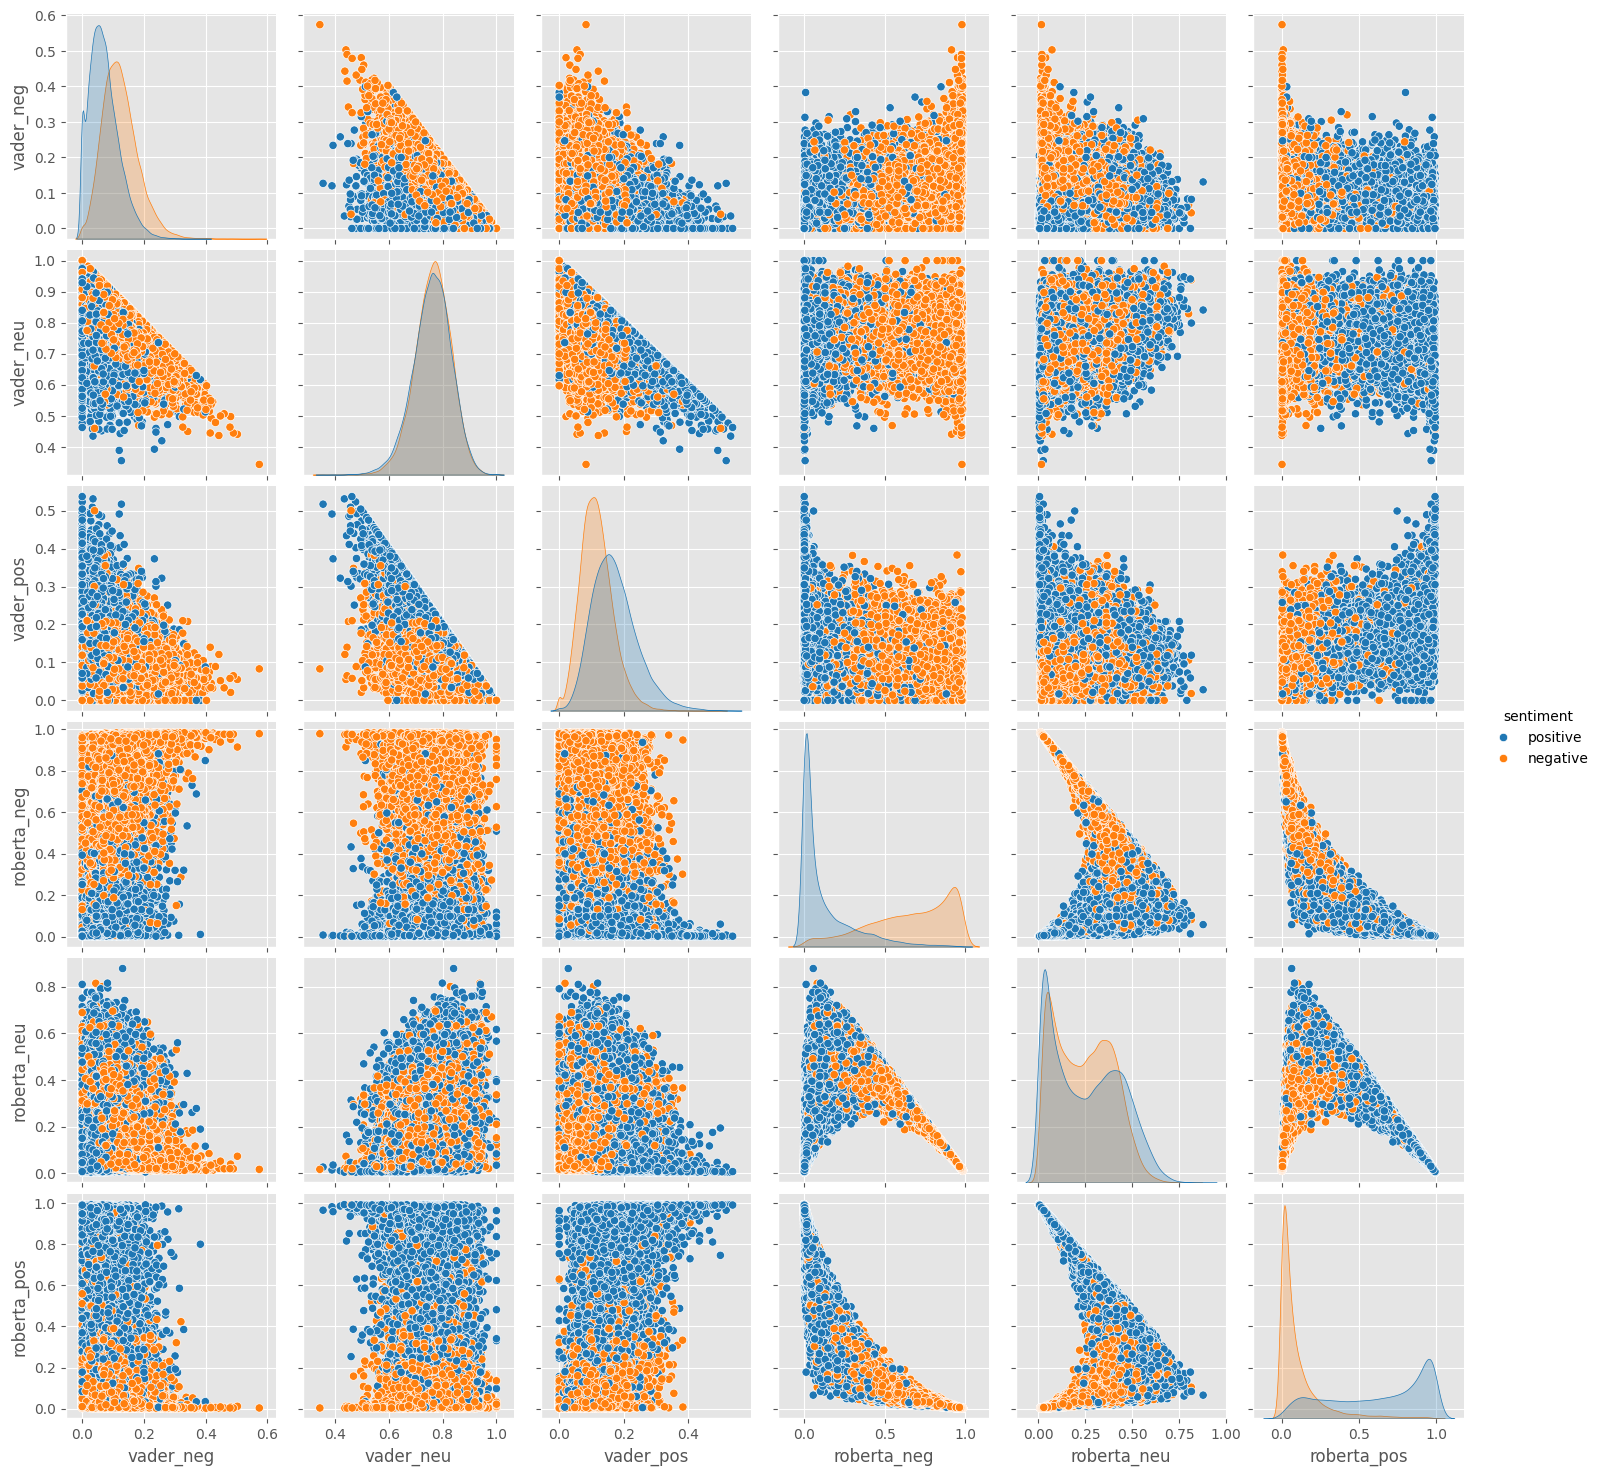

In [17]:
sns.pairplot(data = results_df,
             vars = ['vader_neg', 'vader_neu', 'vader_pos',
                    'roberta_neg', 'roberta_neu', 'roberta_pos'],
            hue = 'sentiment',
            palette = 'tab10')

## 5. DistilBERT Sentiment Analysis

DistilBERT is a lightweight transformer model fine-tuned for binary sentiment classification. Unlike RoBERTa in this project, which produces negative, neutral, and positive scores, DistilBERT directly predicts either positive or negative sentiment.


In [18]:
from transformers import pipeline

In [19]:
distilbert_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=0,
    truncation=True
)

/usr/local/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [20]:
distilbert_results = []
batch_size = 64

for i in tqdm(range(0, len(df), batch_size)):
    batch = df["review"].iloc[i:i + batch_size].tolist()

    batch_results = distilbert_pipeline(
        batch,
        batch_size=batch_size
    )

    for result in batch_results:
        distilbert_results.append({
            "distilbert_prediction": result["label"].lower(),
            "distilbert_score": result["score"]
        })

  0%|          | 0/782 [00:00<?, ?it/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [21]:
distilbert_df = pd.DataFrame(distilbert_results)
#print(distilbert_df.head())
#print(distilbert_df.shape)

```
review
   ↓
DistilBERT
   ↓
label + score
```


In [22]:
results_df = pd.concat(
    [results_df, distilbert_df],
    axis=1
)

print(results_df.head())
print(results_df.shape)

   Id  vader_neg  vader_neu  vader_pos  vader_compound  roberta_neg  \
0   0      0.202      0.750      0.048         -0.9951     0.378364   
1   1      0.055      0.768      0.177          0.9641     0.003819   
2   2      0.093      0.689      0.218          0.9780     0.138401   
3   3      0.137      0.777      0.086         -0.8819     0.750838   
4   4      0.052      0.786      0.162          0.9803     0.021584   

   roberta_neu  roberta_pos sentiment distilbert_prediction  distilbert_score  
0     0.455815     0.165821  positive              negative          0.597333  
1     0.034171     0.962010  positive              positive          0.999253  
2     0.345056     0.516543  positive              positive          0.999081  
3     0.212437     0.036725  negative              negative          0.996536  
4     0.230743     0.747673  positive              positive          0.999079  
(50000, 11)


Since the dataset contains only two sentiment classes, positive and negative, I use VADER's compound score to convert its output into a binary prediction. A score of 0 or higher is classified as positive, while a score below 0 is classified as negative.


In [23]:
results_df["vader_prediction"] = np.where(
    results_df["vader_compound"] >= 0,
    "positive",
    "negative"
)

In [24]:
results_df["vader_prediction"].value_counts()

vader_prediction
positive    33010
negative    16990
Name: count, dtype: int64

RoBERTa produces three sentiment scores: negative, neutral, and positive. Since the dataset contains only positive and negative labels, I compare the negative and positive scores and assign the class with the higher score as the final prediction. The neutral score is therefore not directly assigned to either class.


In [25]:
results_df["roberta_prediction"] = np.where(
    results_df["roberta_pos"] > results_df["roberta_neg"],
    "positive",
    "negative"
)   

In [26]:
results_df["roberta_prediction"].value_counts()

roberta_prediction
negative    27069
positive    22931
Name: count, dtype: int64

## 6. Model Evaluation

To see how well each model performs, I compare its predictions with the actual sentiment labels from the dataset. The confusion matrices give a more detailed view of the results by showing how many positive and negative reviews were classified correctly and how many were misclassified.


In [27]:
from sklearn import metrics

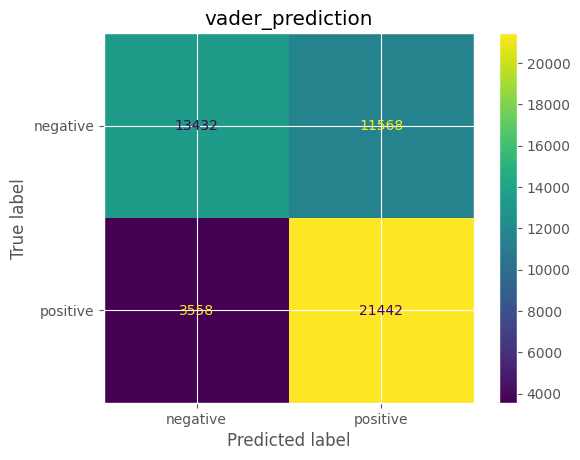

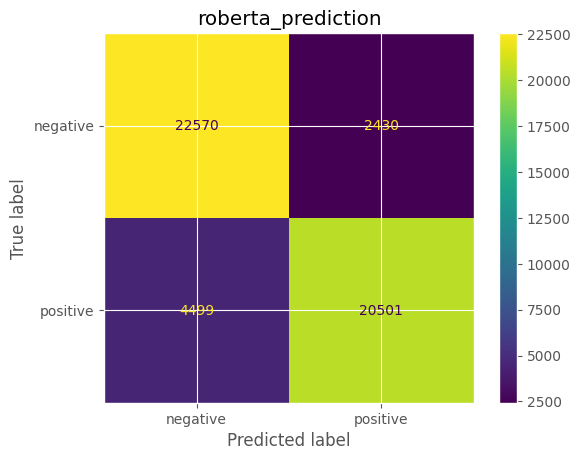

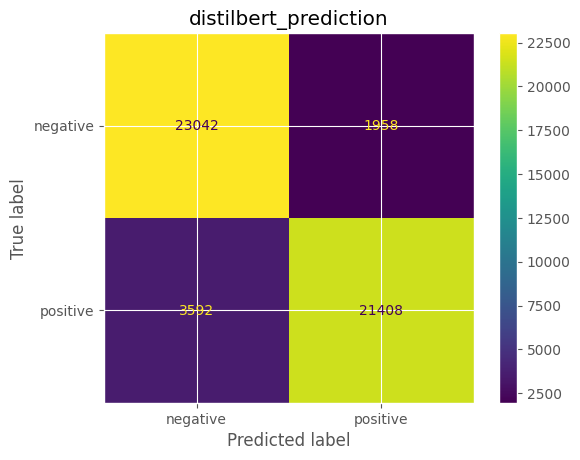

In [28]:
models = [
    "vader_prediction",
    "roberta_prediction",
    "distilbert_prediction"
]

actual = results_df["sentiment"]

for model_name in models:
    predicted = results_df[model_name]

    cm = metrics.confusion_matrix(
        actual,
        predicted
    )

    cm_display = metrics.ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["negative", "positive"]
    )

    cm_display.plot()
    plt.title(model_name)
    plt.show()

To compare the models more clearly, I use accuracy, precision, recall, and F1-score. Each metric highlights a different aspect of the predictions, so looking at all four gives a more complete picture of model performance.

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [30]:
metrics_results = {}

for model_name in models:
    predicted = results_df[model_name]

    accuracy = accuracy_score(actual, predicted)
    precision = precision_score(
        actual,
        predicted,
        pos_label="positive"
    )
    recall = recall_score(
        actual,
        predicted,
        pos_label="positive"
    )
    f1 = f1_score(
        actual,
        predicted,
        pos_label="positive"
    )

    metrics_results[model_name] = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

data = pd.DataFrame.from_dict(metrics_results).T

print(data)

                       accuracy  precision   recall        f1
vader_prediction        0.69748   0.649561  0.85768  0.739252
roberta_prediction      0.86142   0.894030  0.82004  0.855438
distilbert_prediction   0.88900   0.916203  0.85632  0.885250


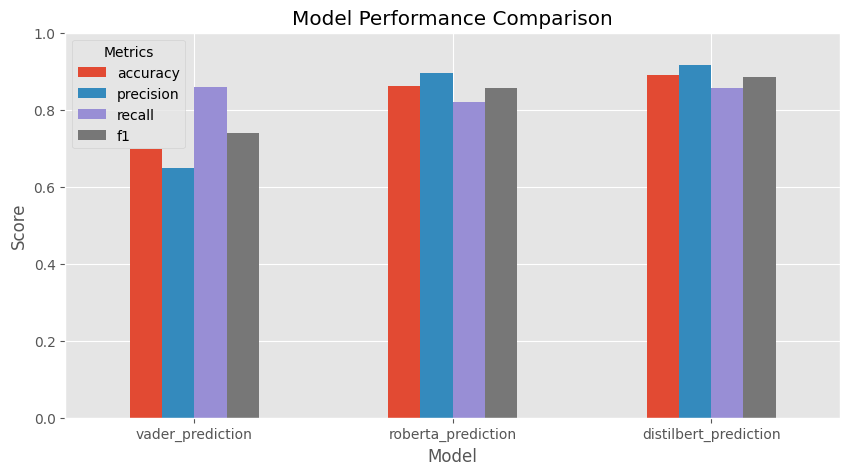

In [31]:
data.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Metrics")
plt.show()

### Prediction Examples

Before examining the models' errors, it is useful to look at some individual predictions. 
First, we examine an example where all three models correctly classified the sentiment of the review.

In [32]:
def show_example(subset):
    example = subset.iloc[0]
    review_text = df.loc[df["Id"] == example["Id"], "review"].values[0]

    print("Review:")
    print(review_text)
    print("\nTrue label:", example["sentiment"])
    print("VADER prediction:", example["vader_prediction"])
    print("RoBERTa prediction:", example["roberta_prediction"])
    print("DistilBERT prediction:", example["distilbert_prediction"])

In [33]:
# all three models correct
all_correct = results_df[
    (results_df["vader_prediction"] == results_df["sentiment"]) &
    (results_df["roberta_prediction"] == results_df["sentiment"]) &
    (results_df["distilbert_prediction"] == results_df["sentiment"])
]

print("Correct by all three models:", len(all_correct), "\n")
show_example(all_correct)

Correct by all three models: 30592 

Review:
A wonderful little production. The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terribly wel

This review is easy for all three models. It is clearly positive from start to finish and uses many direct positive words such as "wonderful", "masterful" and "terrificly written". There is no contrast or irony, so even a word based method like VADER classifies it correctly.

Next, I look at a review that all three models misclassified.

In [34]:
# all three models wrong
all_wrong = results_df[
    (results_df["vader_prediction"] != results_df["sentiment"]) &
    (results_df["roberta_prediction"] != results_df["sentiment"]) &
    (results_df["distilbert_prediction"] != results_df["sentiment"])
]

print("Wrong by all three models:", len(all_wrong), "\n")
show_example(all_wrong)

Wrong by all three models: 2020 

Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you will be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word. It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Them City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away. I would say the main appeal of the show is d

This review is positive, but all three models classify it as negative. Most of the text describes what the show is about, and the show is about violence, drugs, injustice and life in prison. Words like "brutality", "violence", "nasty", "kill" and "death stares" dominate the review, even though the reviewer is describing the content of the show and not giving an opinion about its quality. The actual positive opinion is expressed indirectly, for example "you will be hooked", "it goes where other shows would not dare" and "I developed a taste for Oz". There are almost no direct positive words, so the negative vocabulary of the plot description outweighs the reviewer's real opinion. 2,020 reviews were misclassified by all three models.

The following review was misclassified only by VADER, while both transformer models got it right.

In [35]:
# only VADER wrong
only_vader_wrong = results_df[
    (results_df["vader_prediction"] != results_df["sentiment"]) &
    (results_df["roberta_prediction"] == results_df["sentiment"]) &
    (results_df["distilbert_prediction"] == results_df["sentiment"])
]

print("Wrong only by VADER:", len(only_vader_wrong), "\n")
show_example(only_vader_wrong)

Wrong only by VADER: 10247 

Review:
This show was an amazing, fresh & innovative idea in the 70's when it first aired. The first 7 or 8 years were brilliant, but things dropped off after that. By 1990, the show was not really funny anymore, and it is continued its decline further to the complete waste of time it is today. It is truly disgraceful how far this show has fallen. The writing is painfully bad, the performances are almost as bad - if not for the mildly entertaining respite of the guest-hosts, this show probably would not still be on the air. I find it so hard to believe that the same creator that hand-selected the original cast also chose the band of hacks that followed. How can one recognize such brilliance and then see fit to replace it with such mediocrity? I felt I must give 2 stars out of respect for the original cast that made this show such a huge success. As it is now, the show is just awful. I cannot believe it is still on the air.

True label: negative
VADER predic

VADER predicts positive because the review contains many strongly positive words, such as "amazing", "brilliant", "brilliance" and "huge success". However, these words describe the show in the past. The reviewer's actual opinion is about the show today, which they call "painfully bad" and "awful". VADER adds up the polarity of individual words and cannot see this contrast between past and present, while the transformer models use the context and get it right. This type of error is very common: 10,247 reviews were misclassified only by VADER.

Finally, the opposite case: a review that VADER got right but both transformer models got wrong.

In [36]:
# only VADER right
only_vader_right = results_df[
    (results_df["vader_prediction"] == results_df["sentiment"]) &
    (results_df["roberta_prediction"] != results_df["sentiment"]) &
    (results_df["distilbert_prediction"] != results_df["sentiment"])
]

print("Right only by VADER:", len(only_vader_right), "\n")
show_example(only_vader_right)

Right only by VADER: 1298 

Review:
I saw this movie when I was about 12 when it came out. I recall the scariest scene was the big bird eating men dangling helplessly from parachutes right out of the air. The horror. The horror. As a young kid going to these cheesy B films on Saturday afternoons, I still was tired of the formula for these monster type movies that usually included the hero, a beautiful woman who might be the daughter of a professor and a happy resolution when the monster died in the end. I did not care much for the romantic angle as a 12 year old and the predictable plots. I love them now for the unintentional humor. But, about a year or so later, I saw Psycho when it came out and I loved that the star, Janet Leigh, was bumped off early in the film. I sat up and took notice at that point. Since screenwriters are making up the story, make it up to be as scary as possible and not from a well-worn formula. There are no rules.

True label: negative
VADER prediction: negativ

This is a harder case. The review is mostly a personal memory of watching monster films as a child, and it says very little directly about the film itself. The transformers probably react to phrases like "I love them now" and "I loved that", which are positive but refer to other films (B movies in general and Psycho). VADER predicts negative because of words such as "horror", "scariest", "tired" and "predictable". VADER may get the right answer for the wrong reason here, since these words mostly describe the genre rather than the reviewer's opinion. This case is much rarer: only 1,298 reviews were classified correctly by VADER alone.

## 7. Error Analysis

In this section I look more closely at the errors of each model. First, I check what kind of errors each model makes: predicting positive for a negative review (false positive) or predicting negative for a positive review (false negative).

In [37]:
results_df["vader_correct"] = results_df["vader_prediction"] == results_df["sentiment"]
results_df["roberta_correct"] = results_df["roberta_prediction"] == results_df["sentiment"]
results_df["distilbert_correct"] = results_df["distilbert_prediction"] == results_df["sentiment"]

correct_cols = ["vader_correct", "roberta_correct", "distilbert_correct"]

for model_name in models:
    false_pos = ((results_df[model_name] == "positive") & (results_df["sentiment"] == "negative")).sum()
    false_neg = ((results_df[model_name] == "negative") & (results_df["sentiment"] == "positive")).sum()
    print(model_name)
    print("  False positives:", false_pos)
    print("  False negatives:", false_neg)

vader_prediction
  False positives: 11568
  False negatives: 3558
roberta_prediction
  False positives: 2430
  False negatives: 4499
distilbert_prediction
  False positives: 1958
  False negatives: 3592


The three models make different kinds of errors. VADER has a strong positive bias: it predicts positive for around 33,000 reviews, although only 25,000 are positive. This is partly caused by the threshold, since every review with a compound score of 0 or higher is classified as positive, and partly because movie reviews often contain positive words even when the overall opinion is negative. RoBERTa goes in the opposite direction and makes more false negatives than false positives. One possible reason is that it was trained on tweets and has a neutral class, so long and mixed movie reviews often get a high neutral score, and the decision between positive and negative depends on small differences. DistilBERT has the most balanced errors.

Next, I check whether the length of a review affects accuracy. Both transformer models only read the first 512 tokens (roughly 350 to 400 words), so the end of long reviews is cut off.

              vader_correct  roberta_correct  distilbert_correct
length_group                                                    
0-100              0.749187         0.898341            0.906962
100-200            0.703365         0.884105            0.900434
200-300            0.680030         0.860433            0.894445
300-400            0.662382         0.839974            0.886033
400+               0.677992         0.762626            0.825681
length_group
0-100       6148
100-200    23271
200-300     9379
300-400     4668
400+        6534
Name: count, dtype: int64


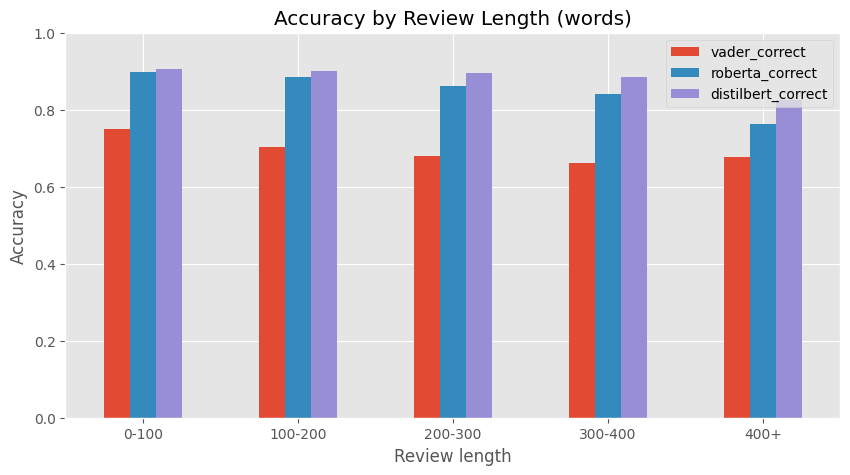

In [38]:
length_map = df.set_index("Id")["review"].str.split().str.len()
results_df["review_length"] = results_df["Id"].map(length_map)

results_df["length_group"] = pd.cut(
    results_df["review_length"],
    bins=[0, 100, 200, 300, 400, 10000],
    labels=["0-100", "100-200", "200-300", "300-400", "400+"]
)

length_accuracy = results_df.groupby("length_group", observed=True)[correct_cols].mean()
print(length_accuracy)
print(results_df["length_group"].value_counts().sort_index())

length_accuracy.plot(kind="bar", figsize=(10, 5))
plt.title("Accuracy by Review Length (words)")
plt.xlabel("Review length")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

All three models become less accurate as reviews get longer, which suggests that long reviews are harder in general, probably because they contain more plot description and more mixed opinions. However, the drop is much larger for the transformer models in the longest group. RoBERTa goes from 0.90 on short reviews to 0.76 on reviews over 400 words, and DistilBERT from 0.91 to 0.83. VADER, which reads the whole text, does not drop further in this group. This fits with the 512 token limit: for the longest reviews, the transformers do not see the end of the text, where reviewers often give their final verdict.

Finally, I check how confident the transformer models are when they make mistakes.

In [39]:
print("DistilBERT confidence score:")
print(results_df.groupby("distilbert_correct")["distilbert_score"].mean())

print("\nRoBERTa neutral score:")
print(results_df.groupby("roberta_correct")["roberta_neu"].mean())

DistilBERT confidence score:
distilbert_correct
False    0.907773
True     0.983332
Name: distilbert_score, dtype: float64

RoBERTa neutral score:
roberta_correct
False    0.400595
True     0.222324
Name: roberta_neu, dtype: float64


The two transformer models behave very differently when they are wrong. DistilBERT is almost as confident in its wrong predictions (average score 0.91) as in its correct ones (0.98), so its confidence score does not tell us much about when it is making a mistake. RoBERTa, on the other hand, gives a much higher neutral score to the reviews it gets wrong (0.40 compared to 0.22). This means that many of its errors happen on reviews it finds unclear, which supports the idea that a model trained on short tweets struggles with long and mixed movie reviews.

## 8. Conclusion

In this project I compared three approaches to sentiment analysis on 50,000 movie reviews. DistilBERT performed best, with an accuracy of 0.889 and an F1 score of 0.885, followed closely by RoBERTa (0.861 accuracy). VADER performed clearly worse, with an accuracy of 0.697.

The error analysis showed that the models fail in different ways. VADER has a strong positive bias and is easily misled by positive words that do not reflect the reviewer's overall opinion, for example when a reviewer praises the past of a show before criticising its present. The transformer models handle this kind of context much better, which is why over 10,000 reviews were misclassified only by VADER. All three models struggle with reviews that describe a dark or violent plot while expressing a positive opinion indirectly, and with very long reviews. For the transformers, long reviews are especially difficult because of the 512 token limit.

This project has some limitations. None of the models were trained on movie reviews: RoBERTa was trained on tweets and DistilBERT on short sentences from the SST-2 dataset. VADER's threshold of 0 was not tuned, and a different threshold would probably reduce its positive bias. Finally, long reviews were truncated instead of being processed in full.

With more time, I would fine-tune one of the transformer models on part of this dataset, since training on movie reviews would likely improve performance a lot. I would also try splitting long reviews into chunks and combining the predictions, and test different thresholds for VADER.